### introduction
the way scikit learn works is that you give it data to model and than that model makes a prediction

the dataset can be split up into 2 parts: X, y

X is the data which trains the model

y is the data which test if model makes correct prediction

so X is used to make model learn pattern to make predictions.


In [2]:
from sklearn.datasets import fetch_california_housing
import matplotlib.pyplot as plt

In [3]:
X, y = fetch_california_housing(return_X_y=True)
# print(X, y)

when you create a model it does not do anything. 
all models are python objects.
there are 2 phases a model has to go through
1. create -> object
2. learn -> fit(X,y) # this is a method of object which is used to train model to make predictions
afterwards the model is ready to make predictions

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression

# model assigned to a variable
# this is the create phase

# mod = LinearRegression()
mod = KNeighborsRegressor()

# this is the learn phase
mod.fit(X,y)

# both .fit and .predict are apis
# even if we change the model we can still use the same api to learn and predict models.
# this helps us to stick with apis and not be concerned with internals of a model.
mod.predict(X)

array([2.826802, 2.1594  , 3.650404, ..., 1.2882  , 1.4418  , 1.7342  ],
      shape=(20640,))

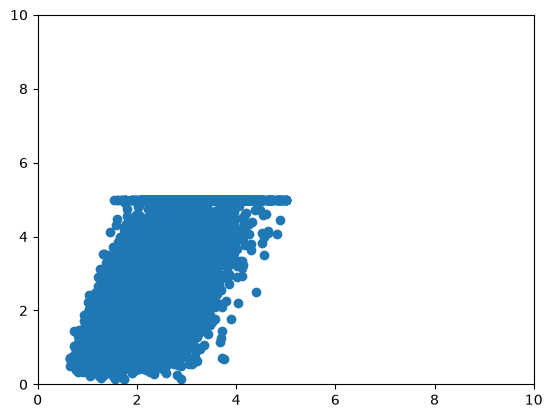

In [11]:
# plotting the predictions on x axis and predicted values on y axis
pred = mod.predict(X)
plt.scatter(pred, y)
# plt.margins(0.2)
plt.xlim(0,10)
plt.ylim(0,10)
plt.show()


the parameters X and y can be in different units, so for that reason we have to ensure that they become same.
so for that reason we scale (preprocess) the X to match the appropriate units of y.

so now our structure becomes
data -> (X, y)
X -> model(scale + KNN) -> pred
y -> model -> pred

now our predictions would be different than before
so now we have a model being =  to scale + KNN
in scikit learn this is called a pipeline

a pipeline is a tool that chains multiple data processing steps and a ML model into a single, cohesive obj

the pipeline also have .fit and .predict apis.
so now this works better as we can just interact with one obj instead of many.

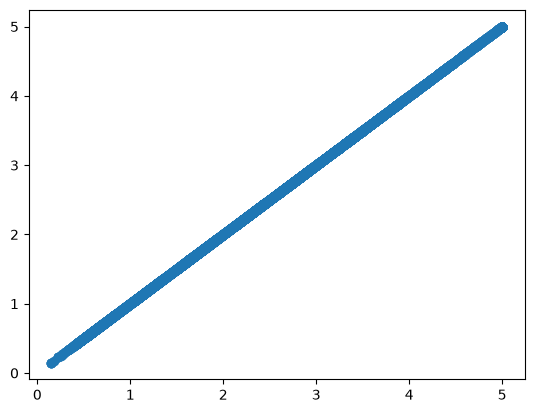

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

mod = KNeighborsRegressor().fit(X, y)
pipe = Pipeline([
    ("scale", StandardScaler()),     # pass 2nd arg as obj not class, hence we put "()"
    ("model", KNeighborsRegressor(n_neighbors=1))
])
pipe.fit(X,y)
pred = pipe.predict(X)
plt.scatter(pred, y)
plt.show()